# EDA

Базовый аудит данных и структуры target перед моделированием.

Основные задачи:

* проверить целостность исходных данных;
* посмотреть динамику GMV и пользовательской активности во времени;
* оценить распределение 30-дневного target;
* проверить изменение target между временными режимами;
* посмотреть основные пользовательские состояния;
* отдельно проверить Search / Catalog;
* оценить, есть ли выраженная кластерная структура.


In [1]:
from __future__ import annotations

import gc
import math
import warnings
from datetime import date, timedelta
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

from IPython.display import display
from scipy.stats import rankdata
from sklearn.cluster import KMeans
from sklearn.decomposition import NMF, PCA
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import RobustScaler

warnings.filterwarnings("ignore")

SEED = 42
HORIZON = 30

FAST_MODE = False

RUN_CLUSTERABILITY = True
RUN_HDBSCAN = not FAST_MODE
RUN_SOFT_PROFILES = True
RUN_ARCHETYPAL_ANALYSIS_IF_AVAILABLE = not FAST_MODE

OUT_DIR = Path("eda_artifacts")
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Загрузка данных

In [2]:
def find_file(*names: str) -> Path | None:
    roots = [
        Path("."),
        Path("data"),
        Path("../data"),
        Path("/mnt/data"),
        Path("/content"),
        Path("/content/data"),
        Path("/kaggle/input"),
    ]
    for root in roots:
        if not root.exists():
            continue
        for name in names:
            p = root / name
            if p.exists():
                return p
        try:
            for name in names:
                hit = next(root.rglob(name), None)
                if hit is not None:
                    return hit
        except Exception:
            pass
    return None


TRAIN_PATH = find_file("train.parquet", "train(1).parquet")
SAMPLE_PATH = find_file(
    "sample_submit.csv",
    "sample_submit(1).csv",
    "sample_submission.csv",
)

if TRAIN_PATH is None:
    raise FileNotFoundError("Не найден train.parquet")

data = pl.read_parquet(TRAIN_PATH)
if data.schema["event_date"] != pl.Date:
    data = data.with_columns(pl.col("event_date").cast(pl.Date))

min_date = data["event_date"].min()
max_date = data["event_date"].max()

if SAMPLE_PATH is not None:
    submit_template = pl.read_csv(SAMPLE_PATH).select("user_id")
    all_users = submit_template.unique(maintain_order=True)
else:
    submit_template = None
    all_users = data.select("user_id").unique().sort("user_id")

EXPECTED_COLUMNS = [
    "event_date", "user_id", "search", "cat",
    "has_search_to_cart", "has_search_to_ord",
    "has_cat_to_cart", "has_cat_to_ord",
    "search_to_cart", "search_to_ord",
    "cat_to_cart", "cat_to_ord",
    "gmv_search", "gmv_cat",
    "to_cart", "to_ord", "gmv", "searches",
]

missing = sorted(set(EXPECTED_COLUMNS) - set(data.columns))
extra = sorted(set(data.columns) - set(EXPECTED_COLUMNS))


assert not missing, f"Не хватает столбцов: {missing}"

## 2. Целостность данных

Проверяем базовые свойства датасета:

* число строк и пользователей;
* диапазон дат;
* дубли `(user_id, event_date)`;
* пропуски и отрицательные значения;
* корректность бинарных признаков;
* согласованность агрегатов Search / Catalog с общими значениями.

Эти проверки нужны до построения любых исторических агрегатов и target.

Отдельно проверяем, что общие показатели совпадают с суммой Search и Catalog.


In [3]:
BINARY_COLS = [
    "search", "cat",
    "has_search_to_cart", "has_search_to_ord",
    "has_cat_to_cart", "has_cat_to_ord",
]
NONNEG_COLS = [
    "search_to_cart", "search_to_ord", "cat_to_cart", "cat_to_ord",
    "gmv_search", "gmv_cat", "to_cart", "to_ord", "gmv", "searches",
]

n_rows = data.height
n_users_data = data["user_id"].n_unique()
n_user_days = data.select(pl.struct(["user_id", "event_date"]).n_unique()).item()
duplicate_user_day_rows = n_rows - n_user_days

null_counts = (
    data.null_count()
    .transpose(
        include_header=True,
        header_name="column",
        column_names=["null_count"],
    )
    .sort("null_count", descending=True)
)

binary_bad = pl.DataFrame([
    {
        "column": c,
        "invalid_binary_rows": data.filter(~pl.col(c).is_in([0, 1])).height,
    }
    for c in BINARY_COLS
])

negative_counts = pl.DataFrame([
    {
        "column": c,
        "negative_rows": data.filter(pl.col(c) < 0).height,
    }
    for c in NONNEG_COLS
])

identity_summary = data.select([
    (pl.col("gmv") - pl.col("gmv_search") - pl.col("gmv_cat"))
        .abs().mean().alias("gmv_channel_mae"),
    (pl.col("gmv") - pl.col("gmv_search") - pl.col("gmv_cat"))
        .abs().max().alias("gmv_channel_max_abs"),
    (pl.col("to_ord") - pl.col("search_to_ord") - pl.col("cat_to_ord"))
        .abs().mean().alias("orders_channel_mae"),
    (pl.col("to_cart") - pl.col("search_to_cart") - pl.col("cat_to_cart"))
        .abs().mean().alias("cart_channel_mae"),
])

flag_checks = data.select([
    ((pl.col("has_search_to_cart") > 0) != (pl.col("search_to_cart") > 0))
        .sum().alias("search_cart_flag_mismatch"),
    ((pl.col("has_search_to_ord") > 0) != (pl.col("search_to_ord") > 0))
        .sum().alias("search_ord_flag_mismatch"),
    ((pl.col("has_cat_to_cart") > 0) != (pl.col("cat_to_cart") > 0))
        .sum().alias("cat_cart_flag_mismatch"),
    ((pl.col("has_cat_to_ord") > 0) != (pl.col("cat_to_ord") > 0))
        .sum().alias("cat_ord_flag_mismatch"),
])

integrity = pl.DataFrame({
    "metric": [
        "rows", "users_in_data", "users_in_universe", "unique_user_days",
        "duplicate_user_day_rows", "date_min", "date_max",
    ],
    "value": [
        str(n_rows), str(n_users_data), str(all_users.height), str(n_user_days),
        str(duplicate_user_day_rows), str(min_date), str(max_date),
    ],
})

integrity.write_csv(OUT_DIR / "integrity.csv")
null_counts.write_csv(OUT_DIR / "null_counts.csv")
binary_bad.write_csv(OUT_DIR / "binary_checks.csv")
negative_counts.write_csv(OUT_DIR / "negative_checks.csv")
identity_summary.write_csv(OUT_DIR / "identity_checks.csv")
flag_checks.write_csv(OUT_DIR / "flag_checks.csv")

display(integrity)
display(null_counts.head(20))
display(binary_bad)
display(negative_counts)
display(identity_summary)
display(flag_checks)


metric,value
str,str
"""rows""","""30631006"""
"""users_in_data""","""250000"""
"""users_in_universe""","""250000"""
"""unique_user_days""","""30631006"""
"""duplicate_user_day_rows""","""0"""
"""date_min""","""2025-01-01"""
"""date_max""","""2026-02-13"""


column,null_count
str,u32
"""event_date""",0
"""user_id""",0
"""search""",0
"""cat""",0
"""has_search_to_cart""",0
…,…
"""gmv_cat""",0
"""to_cart""",0
"""to_ord""",0


column,invalid_binary_rows
str,i64
"""search""",0
"""cat""",0
"""has_search_to_cart""",0
"""has_search_to_ord""",0
"""has_cat_to_cart""",0
"""has_cat_to_ord""",0


column,negative_rows
str,i64
"""search_to_cart""",0
"""search_to_ord""",0
"""cat_to_cart""",0
"""cat_to_ord""",0
"""gmv_search""",0
"""gmv_cat""",0
"""to_cart""",0
"""to_ord""",0
"""gmv""",0


gmv_channel_mae,gmv_channel_max_abs,orders_channel_mae,cart_channel_mae
f64,f64,f64,f64
5.2544e-16,5.2751e-11,0.0,0.0


search_cart_flag_mismatch,search_ord_flag_mismatch,cat_cart_flag_mismatch,cat_ord_flag_mismatch
u32,u32,u32,u32
0,0,0,0


## 3. First seen и история пользователя

Для каждого пользователя определяем первую дату появления в данных.

На ранних historical anchors часть пользователей ещё не появилась в истории. Их важно не смешивать с пользователями, которые уже существовали, но не проявляли активности.


In [4]:
first_seen = (
    data.group_by("user_id")
    .agg([
        pl.col("event_date").min().alias("first_event_date"),
        pl.col("event_date").max().alias("last_event_date"),
        pl.len().alias("observed_rows"),
    ])
)

first_seen_full = (
    all_users.join(first_seen, on="user_id", how="left")
    .with_columns([
        pl.col("first_event_date").fill_null(max_date + timedelta(days=1)),
        pl.col("last_event_date").fill_null(min_date - timedelta(days=1)),
        pl.col("observed_rows").fill_null(0),
    ])
)

PRIMARY_ANCHORS = [
    date(2025, 7, 30),
    date(2025, 9, 10),
    date(2025, 10, 22),
    date(2026, 1, 14),
]
STRESS_ANCHORS = [
    date(2025, 6, 18),
    date(2025, 12, 3),
    date(2025, 12, 15),
]
SEASONAL_ANALOGUE = date(max_date.year - 1, max_date.month, max_date.day)

V9_ANCHORS = [
    date(2025, 2, 13), date(2025, 3, 26), date(2025, 5, 7),
    date(2025, 6, 18), date(2025, 7, 30), date(2025, 9, 10),
    date(2025, 10, 22), date(2025, 11, 12), date(2025, 12, 3),
    date(2025, 12, 15), date(2026, 1, 14),
]

cohort_rows = []
for a in V9_ANCHORS:
    if not (min_date <= a <= max_date):
        continue
    n_future_users = first_seen_full.filter(pl.col("first_event_date") > a).height
    cohort_rows.append({
        "anchor": a,
        "n_users": all_users.height,
        "n_seen_by_anchor": all_users.height - n_future_users,
        "n_first_seen_after_anchor": n_future_users,
        "share_first_seen_after_anchor": n_future_users / all_users.height,
    })

cohort_summary = pl.DataFrame(cohort_rows)
cohort_summary.write_csv(OUT_DIR / "first_seen_by_anchor.csv")
display(cohort_summary)


anchor,n_users,n_seen_by_anchor,n_first_seen_after_anchor,share_first_seen_after_anchor
date,i64,i64,i64,f64
2025-02-13,250000,197871,52129,0.208516
2025-03-26,250000,211754,38246,0.152984
2025-05-07,250000,219428,30572,0.122288
2025-06-18,250000,225245,24755,0.09902
2025-07-30,250000,230659,19341,0.077364
…,…,…,…,…
2025-10-22,250000,241469,8531,0.034124
2025-11-12,250000,244550,5450,0.0218
2025-12-03,250000,247929,2071,0.008284


## 4. Динамика площадки

Смотрим изменение GMV, заказов, числа покупателей и активных пользователей во времени.

30-дневное скользящее среднее используется, чтобы отделить общий тренд от дневного шума.


month,mean_daily_active_users,mean_daily_buyers,mean_buyer_rate,gmv,orders,searches,gmv_search,gmv_cat,gmv_search_share
date,f64,f64,f64,f64,i64,i64,f64,f64,f64
2025-01-01,57107.387097,7776.774194,0.136121,1.4558e7,402490,5718814,1.3239e7,1.3197e6,0.90935
2025-02-01,61792.464286,8779.321429,0.141949,1.4485e7,416789,5601636,1.3218e7,1.2672e6,0.912516
2025-03-01,64186.064516,9301.16129,0.144852,1.7418e7,489485,6277483,1.5953e7,1.4653e6,0.915872
2025-04-01,64914.8,9380.3,0.14446,1.7006e7,474734,6033422,1.5778e7,1.2274e6,0.927825
2025-05-01,65439.83871,9693.032258,0.14798,1.7757e7,510083,6343306,1.6482e7,1.2752e6,0.928188
…,…,…,…,…,…,…,…,…,…
2025-10-01,84472.709677,13591.612903,0.160903,2.3535e7,714659,8537800,2.1777e7,1.7586e6,0.925278
2025-11-01,92522.033333,14483.333333,0.156484,2.3998e7,739395,9182603,2.2321e7,1.6778e6,0.930089
2025-12-01,95760.967742,15877.806452,0.165441,2.8815e7,850507,9908577,2.6884e7,1.9305e6,0.933003


weekday,mean_gmv,mean_orders,mean_buyers,mean_buyer_rate,mean_search_share
i8,f64,f64,f64,f64,f64
1,677063.643419,19841.431034,11740.0,0.152733,0.926514
2,677530.675163,20040.948276,11834.362069,0.154232,0.926594
3,675413.185004,19894.559322,11780.288136,0.155227,0.925258
4,664661.151659,19551.79661,11577.372881,0.153242,0.92505
5,638763.600888,18768.220339,11065.271186,0.150711,0.925735
6,643691.939358,19117.293103,11117.517241,0.153468,0.924249
7,680164.358276,20609.086207,11962.5,0.155856,0.925142


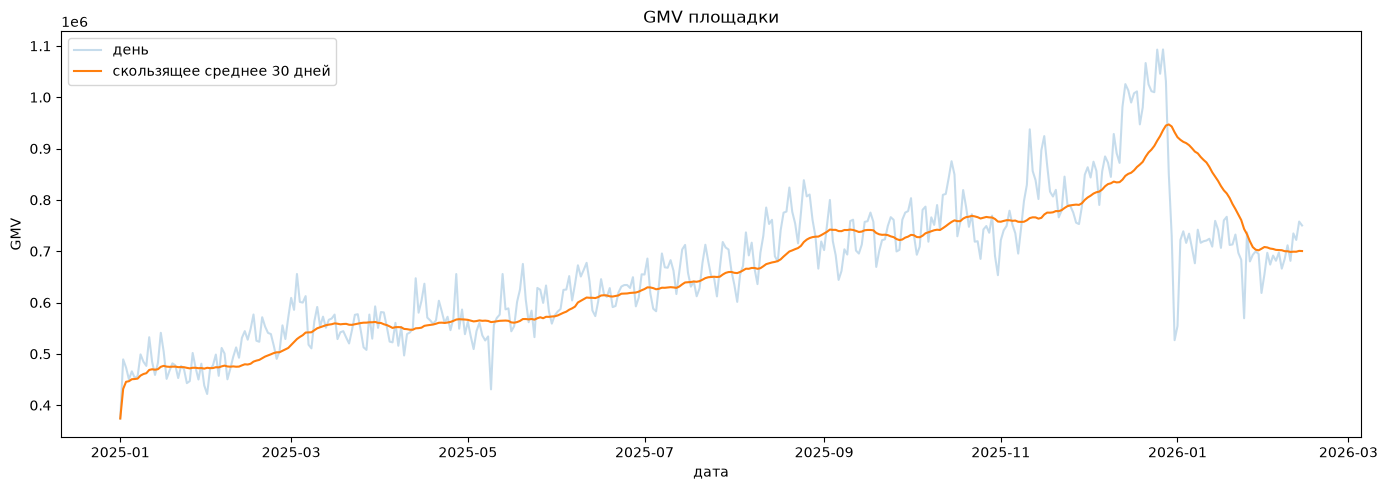

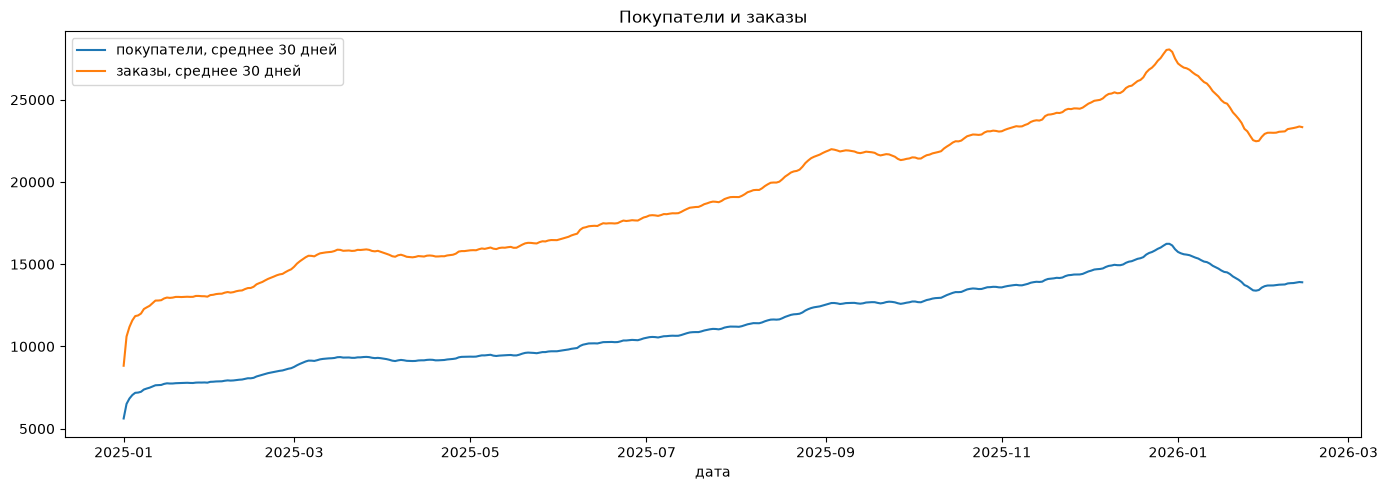

In [5]:
daily = (
    data.group_by("event_date")
    .agg([
        pl.col("user_id").n_unique().alias("active_users"),
        pl.col("user_id").filter(pl.col("to_ord") > 0).n_unique().alias("buyers"),
        pl.col("gmv").sum().alias("gmv"),
        pl.col("gmv_search").sum().alias("gmv_search"),
        pl.col("gmv_cat").sum().alias("gmv_cat"),
        pl.col("to_ord").sum().alias("orders"),
        pl.col("to_cart").sum().alias("carts"),
        pl.col("searches").sum().alias("searches"),
    ])
    .sort("event_date")
    .with_columns([
        (pl.col("buyers") / pl.col("active_users").clip(lower_bound=1)).alias("buyer_rate"),
        (pl.col("gmv") / pl.col("buyers").clip(lower_bound=1)).alias("gmv_per_buyer"),
        (pl.col("orders") / pl.col("buyers").clip(lower_bound=1)).alias("orders_per_buyer"),
        (pl.col("gmv_search") / (pl.col("gmv") + 1e-9)).alias("gmv_search_share"),
    ])
    .with_columns([
        pl.col("gmv").rolling_mean(window_size=30, min_samples=1).alias("gmv_ma30"),
        pl.col("buyers").rolling_mean(window_size=30, min_samples=1).alias("buyers_ma30"),
        pl.col("orders").rolling_mean(window_size=30, min_samples=1).alias("orders_ma30"),
        pl.col("searches").rolling_mean(window_size=30, min_samples=1).alias("searches_ma30"),
    ])
)

monthly = (
    daily.with_columns(pl.col("event_date").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .agg([
        pl.col("active_users").mean().alias("mean_daily_active_users"),
        pl.col("buyers").mean().alias("mean_daily_buyers"),
        pl.col("buyer_rate").mean().alias("mean_buyer_rate"),
        pl.col("gmv").sum().alias("gmv"),
        pl.col("orders").sum().alias("orders"),
        pl.col("searches").sum().alias("searches"),
        pl.col("gmv_search").sum().alias("gmv_search"),
        pl.col("gmv_cat").sum().alias("gmv_cat"),
    ])
    .sort("month")
    .with_columns(
        (pl.col("gmv_search") / (pl.col("gmv") + 1e-9)).alias("gmv_search_share")
    )
)

weekday = (
    daily.with_columns(pl.col("event_date").dt.weekday().alias("weekday"))
    .group_by("weekday")
    .agg([
        pl.col("gmv").mean().alias("mean_gmv"),
        pl.col("orders").mean().alias("mean_orders"),
        pl.col("buyers").mean().alias("mean_buyers"),
        pl.col("buyer_rate").mean().alias("mean_buyer_rate"),
        pl.col("gmv_search_share").mean().alias("mean_search_share"),
    ])
    .sort("weekday")
)

daily.write_csv(OUT_DIR / "daily_platform.csv")
monthly.write_csv(OUT_DIR / "monthly_platform.csv")
weekday.write_csv(OUT_DIR / "weekday_platform.csv")

display(monthly)
display(weekday)

dates = daily["event_date"].to_list()

plt.figure(figsize=(14, 5))
plt.plot(dates, daily["gmv"].to_numpy(), alpha=0.25, label="день")
plt.plot(dates, daily["gmv_ma30"].to_numpy(), label="скользящее среднее 30 дней")
plt.title("GMV площадки")
plt.xlabel("дата")
plt.ylabel("GMV")
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "platform_gmv.png", dpi=140)
plt.show()

plt.figure(figsize=(14, 5))
plt.plot(dates, daily["buyers_ma30"].to_numpy(), label="покупатели, среднее 30 дней")
plt.plot(dates, daily["orders_ma30"].to_numpy(), label="заказы, среднее 30 дней")
plt.title("Покупатели и заказы")
plt.xlabel("дата")
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "platform_buyers_orders.png", dpi=140)
plt.show()


## 5. Исторические 30-дневные targets

Для каждого historical anchor строим тот же target, что и в соревновании - суммарный GMV пользователя за следующие 30 дней.

Сравниваем распределение target между временными периодами, чтобы оценить temporal drift.


In [23]:
HOLIDAY_CODES = {
    221, 222, 223,
    306, 307, 308,
    429, 430, 501,
    507, 508, 509,
    610, 611, 612,
    1102, 1103, 1104,
}

def monthday_code(d: date) -> int:
    return d.month * 100 + d.day

def is_newyear_window_day(d: date) -> bool:
    return (d.month == 12 and d.day >= 15) or (d.month == 1 and d.day <= 3)

def future_calendar_values(anchor: date) -> dict[str, float]:
    days = [anchor + timedelta(days=i) for i in range(1, HORIZON + 1)]
    return {
        "target_special_days": float(sum(
            monthday_code(d) in HOLIDAY_CODES or is_newyear_window_day(d)
            for d in days
        )),
        "target_newyear_days": float(sum(is_newyear_window_day(d) for d in days)),
        "target_weekend_days": float(sum(d.weekday() >= 5 for d in days)),
    }

def target_activity_for_anchor(anchor: date, include_users: bool = False) -> pl.DataFrame:
    start = anchor + timedelta(days=1)
    end = anchor + timedelta(days=HORIZON)
    t = (
        data.filter(pl.col("event_date").is_between(start, end, closed="both"))
        .group_by("user_id")
        .agg([
            pl.col("gmv").sum().alias("future_gmv"),
            pl.col("to_ord").sum().alias("future_to_ord"),
            pl.col("event_date").filter(pl.col("to_ord") > 0).n_unique().alias("future_order_days"),
            pl.col("gmv_search").sum().alias("future_gmv_search"),
            pl.col("gmv_cat").sum().alias("future_gmv_cat"),
        ])
    )
    if include_users:
        t = (
            all_users.join(t, on="user_id", how="left")
            .with_columns([
                pl.col(c).fill_null(0)
                for c in [
                    "future_gmv", "future_to_ord", "future_order_days",
                    "future_gmv_search", "future_gmv_cat",
                ]
            ])
        )
    return t

earliest_target_anchor = max(date(2025, 2, 13), min_date + timedelta(days=43))
latest_target_anchor = max_date - timedelta(days=HORIZON)

if FAST_MODE:
    eda_anchors = sorted(set(
        [a for a in V9_ANCHORS if earliest_target_anchor <= a <= latest_target_anchor]
        + [a for a in PRIMARY_ANCHORS + STRESS_ANCHORS if earliest_target_anchor <= a <= latest_target_anchor]
    ))
else:
    eda_anchors = []
    a = earliest_target_anchor
    while a <= latest_target_anchor:
        eda_anchors.append(a)
        a += timedelta(days=21)
    eda_anchors = sorted(set(
        eda_anchors
        + [a for a in V9_ANCHORS + PRIMARY_ANCHORS + STRESS_ANCHORS if a <= latest_target_anchor]
    ))

target_rows = []
for i, a in enumerate(eda_anchors, 1):
    t = target_activity_for_anchor(a, include_users=False)

    gmv_pos = t.filter(pl.col("future_gmv") > 0)["future_gmv"].to_numpy().astype(np.float64)
    n_pos = len(gmv_pos)
    n_zero = all_users.height - n_pos

    gmv_all = np.concatenate([
        np.zeros(n_zero, dtype=np.float64),
        gmv_pos,
    ])

    cal = future_calendar_values(a)
    total_gmv = float(t["future_gmv"].sum())

    target_rows.append({
        "anchor": a,
        "target_start": a + timedelta(days=1),
        "target_end": a + timedelta(days=HORIZON),
        "zero_share": n_zero / all_users.height,
        "buyers": n_pos,
        "mean_gmv": total_gmv / all_users.height,
        "p50_gmv": float(np.quantile(gmv_all, 0.50)),
        "p90_gmv": float(np.quantile(gmv_all, 0.90)),
        "p95_gmv": float(np.quantile(gmv_all, 0.95)),
        "p99_gmv": float(np.quantile(gmv_all, 0.99)),
        "mean_log1p_gmv": float(np.log1p(gmv_all).mean()),
        "mean_future_order_days": float(t["future_order_days"].sum()) / all_users.height,
        "mean_future_to_ord": float(t["future_to_ord"].sum()) / all_users.height,
        "target_search_share": float(t["future_gmv_search"].sum()) / max(total_gmv, 1e-9),
        **cal,
    })

target_summary = pl.DataFrame(target_rows).sort("anchor")
target_summary.write_csv(OUT_DIR / "target_anchor_summary.csv")

### Target distribution

* `zero_share` - доля пользователей с нулевым GMV в следующие 30 дней;
* `buyers` - число пользователей с положительным target;
* `mean_gmv` - средний 30-дневный GMV по всем пользователям;
* `p50_gmv` ... `p99_gmv` - квантили распределения target;
* `mean_future_order_days` - среднее число дней с заказами в target window;
* `mean_future_to_ord` - среднее число заказов;
* `target_search_share` - доля Search в общем GMV target.


In [24]:
display(target_summary)

anchor,target_start,target_end,zero_share,buyers,mean_gmv,p50_gmv,p90_gmv,p95_gmv,p99_gmv,mean_log1p_gmv,mean_future_order_days,mean_future_to_ord,target_search_share,target_special_days,target_newyear_days,target_weekend_days
date,date,date,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2025-02-13,2025-02-14,2025-03-15,0.597072,100732,66.927018,0.0,172.575783,321.719398,926.7681,1.715443,1.11604,1.896288,0.9146,6.0,0.0,9.0
2025-03-06,2025-03-07,2025-04-05,0.599984,100004,66.063393,0.0,169.502765,321.18251,929.995485,1.693263,1.0935,1.854552,0.918177,2.0,0.0,9.0
2025-03-26,2025-03-27,2025-04-25,0.59646,100885,67.460238,0.0,172.527914,324.358806,964.480445,1.706556,1.108936,1.869192,0.926085,0.0,0.0,8.0
2025-03-27,2025-03-28,2025-04-26,0.595836,101041,67.702709,0.0,173.007374,325.034583,966.573227,1.709937,1.112112,1.87706,0.926493,0.0,0.0,9.0
2025-04-17,2025-04-18,2025-05-17,0.589744,102564,67.283496,0.0,171.910486,325.310659,924.497529,1.728368,1.13462,1.920292,0.929127,6.0,0.0,9.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2025-12-03,2025-12-04,2026-01-02,0.424488,143878,110.036913,14.646608,289.287348,500.035136,1279.235584,2.507679,1.879576,3.248116,0.93303,19.0,19.0,8.0
2025-12-04,2025-12-05,2026-01-03,0.425176,143706,109.566356,14.530562,288.187174,497.388969,1272.572282,2.503406,1.872684,3.234572,0.933117,20.0,20.0,9.0
2025-12-15,2025-12-16,2026-01-14,0.43692,140770,101.425944,12.154563,265.578242,463.565456,1209.716953,2.417045,1.7782,3.043728,0.931113,19.0,19.0,8.0


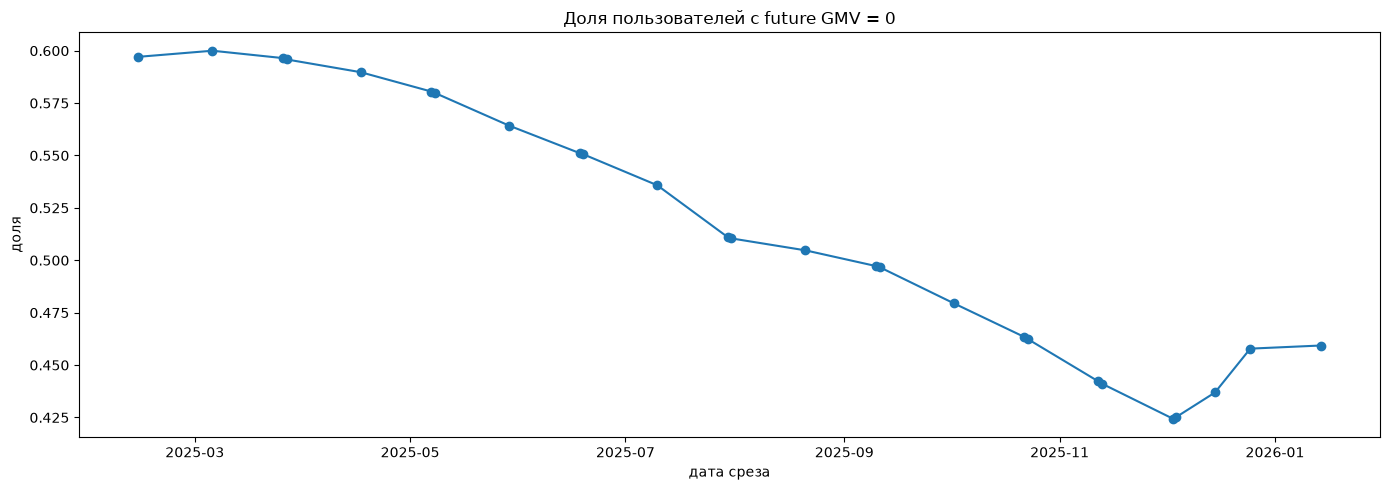

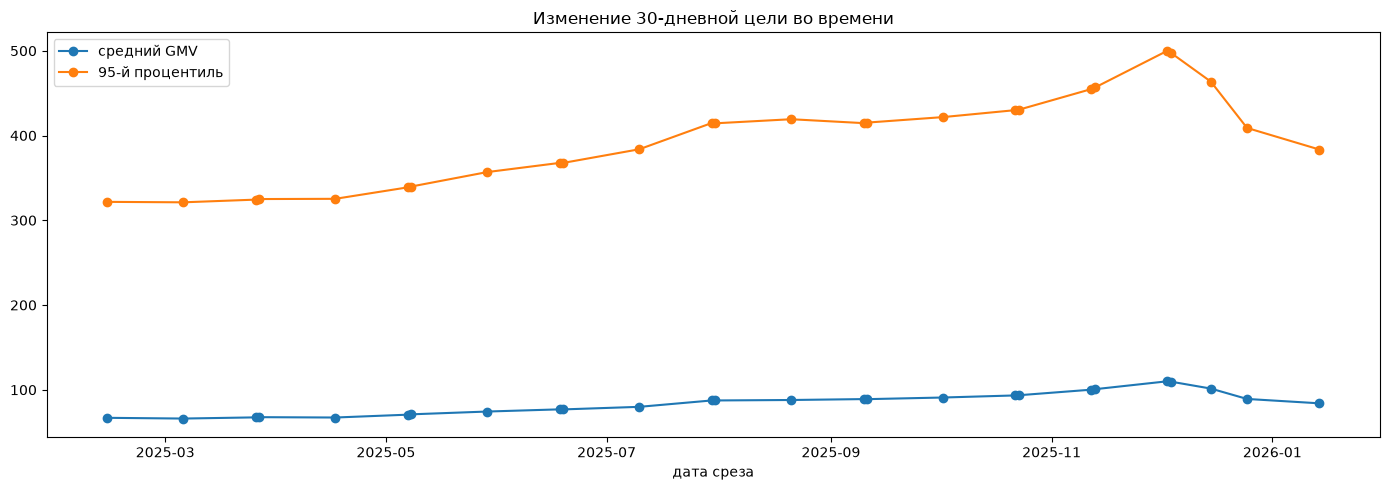

In [25]:
x = target_summary["anchor"].to_list()

plt.figure(figsize=(14, 5))
plt.plot(x, target_summary["zero_share"].to_numpy(), marker="o")
plt.title("Доля пользователей с future GMV = 0")
plt.xlabel("дата среза")
plt.ylabel("доля")
plt.tight_layout()
plt.savefig(OUT_DIR / "target_zero_share.png", dpi=140)
plt.show()

plt.figure(figsize=(14, 5))
plt.plot(x, target_summary["mean_gmv"].to_numpy(), marker="o", label="средний GMV")
plt.plot(x, target_summary["p95_gmv"].to_numpy(), marker="o", label="95-й процентиль")
plt.title("Изменение 30-дневной цели во времени")
plt.xlabel("дата среза")
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "target_level_drift.png", dpi=140)
plt.show()

## 6. User states

Сравниваем future GMV для пользователей с разным текущим состоянием.

Основные оси:

* `recency_bin` - сколько дней прошло с последнего заказа;
* `order_days90_bin` - число дней с заказами за последние 90 дней;
* `history_age_bin` - длина доступной истории пользователя;
* `trend_bin` - изменение числа заказов в последних 30 днях относительно предыдущих 30;
* `hist_channel_bin` - соотношение Search / Catalog в историческом GMV.


In [7]:
RECENCY_SENTINEL = 9999

def make_user_snapshot(anchor: date, with_target: bool = True) -> pl.DataFrame:
    hist_start = max(min_date, anchor - timedelta(days=364))
    hist = data.filter(
        pl.col("event_date").is_between(hist_start, anchor, closed="both")
    )

    exprs = []
    for w in [30, 60, 90, 180, 365]:
        start = anchor - timedelta(days=w - 1)
        m = pl.col("event_date") >= pl.lit(start)
        exprs.extend([
            pl.col("event_date").filter(m).n_unique().alias(f"active_days_{w}"),
            pl.col("event_date").filter(m & (pl.col("to_ord") > 0)).n_unique().alias(f"order_days_{w}"),
            pl.col("to_ord").filter(m).sum().alias(f"orders_{w}"),
            pl.col("gmv").filter(m).sum().alias(f"gmv_{w}"),
            pl.col("searches").filter(m).sum().alias(f"searches_{w}"),
            pl.col("to_cart").filter(m).sum().alias(f"carts_{w}"),
            pl.col("gmv_search").filter(m).sum().alias(f"gmv_search_{w}"),
        ])

    exprs.extend([
        pl.col("event_date").max().alias("_last_active"),
        pl.col("event_date").filter(pl.col("to_ord") > 0).max().alias("_last_order"),
    ])

    agg = hist.group_by("user_id").agg(exprs)

    frame = (
        all_users.join(agg, on="user_id", how="left")
        .join(first_seen.select(["user_id", "first_event_date"]), on="user_id", how="left")
    )

    numeric_fill = [
        c for c in frame.columns
        if c not in ["user_id", "first_event_date", "_last_active", "_last_order"]
    ]
    frame = frame.with_columns([pl.col(c).fill_null(0) for c in numeric_fill])

    frame = frame.with_columns([
        (
            pl.lit(anchor).cast(pl.Date).cast(pl.Int32)
            - pl.col("_last_active").cast(pl.Int32)
        ).fill_null(RECENCY_SENTINEL).alias("recency_active"),
        (
            pl.lit(anchor).cast(pl.Date).cast(pl.Int32)
            - pl.col("_last_order").cast(pl.Int32)
        ).fill_null(RECENCY_SENTINEL).alias("recency_order"),
        (
            pl.lit(anchor).cast(pl.Date).cast(pl.Int32)
            - pl.col("first_event_date").cast(pl.Int32) + 1
        ).fill_null(-1).alias("history_age_days"),
    ]).drop(["_last_active", "_last_order"])

    prev30_orders = (pl.col("orders_60") - pl.col("orders_30")).clip(lower_bound=0)
    prev90_orders = (pl.col("orders_180") - pl.col("orders_90")).clip(lower_bound=0)

    frame = frame.with_columns([
        ((pl.col("orders_30") + 1.0) / (prev30_orders + 1.0)).alias("order_trend_30_vs_prev30"),
        ((pl.col("orders_90") + 1.0) / (prev90_orders + 1.0)).alias("order_trend_90_vs_prev90"),
        (pl.col("orders_30") / pl.col("orders_90").clip(lower_bound=1)).alias("orders_recent_share"),
        (pl.col("gmv_search_365") / (pl.col("gmv_365") + 1e-9))
            .fill_nan(0).alias("hist_search_share"),
        pl.lit(anchor).cast(pl.Date).alias("anchor"),
    ])

    if with_target:
        frame = frame.join(
            target_activity_for_anchor(anchor, include_users=True),
            on="user_id",
            how="left",
        )
        frame = frame.with_columns([
            (pl.col("future_gmv") <= 0).alias("future_zero"),
            (pl.col("future_gmv_search") / (pl.col("future_gmv") + 1e-9))
                .fill_nan(0).alias("future_search_share"),
        ])

    return frame


def add_state_bins(frame: pl.DataFrame) -> pl.DataFrame:
    return frame.with_columns([
        pl.when(pl.col("recency_order") >= RECENCY_SENTINEL).then(pl.lit("never"))
          .when(pl.col("recency_order") <= 7).then(pl.lit("00_0-7"))
          .when(pl.col("recency_order") <= 14).then(pl.lit("01_8-14"))
          .when(pl.col("recency_order") <= 30).then(pl.lit("02_15-30"))
          .when(pl.col("recency_order") <= 60).then(pl.lit("03_31-60"))
          .when(pl.col("recency_order") <= 90).then(pl.lit("04_61-90"))
          .when(pl.col("recency_order") <= 180).then(pl.lit("05_91-180"))
          .otherwise(pl.lit("06_181+")).alias("recency_bin"),

        pl.when(pl.col("order_days_90") == 0).then(pl.lit("00_0"))
          .when(pl.col("order_days_90") == 1).then(pl.lit("01_1"))
          .when(pl.col("order_days_90") == 2).then(pl.lit("02_2"))
          .when(pl.col("order_days_90") <= 4).then(pl.lit("03_3-4"))
          .when(pl.col("order_days_90") <= 8).then(pl.lit("04_5-8"))
          .otherwise(pl.lit("05_9+")).alias("order_days90_bin"),

        pl.when(pl.col("history_age_days") < 0).then(pl.lit("prebirth"))
          .when(pl.col("history_age_days") <= 30).then(pl.lit("00_<=30"))
          .when(pl.col("history_age_days") <= 90).then(pl.lit("01_31-90"))
          .when(pl.col("history_age_days") <= 180).then(pl.lit("02_91-180"))
          .when(pl.col("history_age_days") <= 365).then(pl.lit("03_181-365"))
          .otherwise(pl.lit("04_365+")).alias("history_age_bin"),

        pl.when(pl.col("orders_60") == 0).then(pl.lit("no_orders"))
          .when(pl.col("order_trend_30_vs_prev30") < 0.50).then(pl.lit("00_collapse"))
          .when(pl.col("order_trend_30_vs_prev30") < 0.80).then(pl.lit("01_decline"))
          .when(pl.col("order_trend_30_vs_prev30") <= 1.25).then(pl.lit("02_stable"))
          .when(pl.col("order_trend_30_vs_prev30") <= 2.00).then(pl.lit("03_growth"))
          .otherwise(pl.lit("04_surge")).alias("trend_bin"),

        pl.when(pl.col("gmv_365") <= 0).then(pl.lit("no_gmv"))
          .when(pl.col("hist_search_share") >= 0.80).then(pl.lit("00_search_dom"))
          .when(pl.col("hist_search_share") >= 0.55).then(pl.lit("01_search_lean"))
          .when(pl.col("hist_search_share") >= 0.45).then(pl.lit("02_balanced"))
          .when(pl.col("hist_search_share") >= 0.20).then(pl.lit("03_cat_lean"))
          .otherwise(pl.lit("04_cat_dom")).alias("hist_channel_bin"),

        pl.when(pl.col("future_order_days") == 0).then(pl.lit("00_0"))
          .when(pl.col("future_order_days") == 1).then(pl.lit("01_1"))
          .when(pl.col("future_order_days") == 2).then(pl.lit("02_2"))
          .when(pl.col("future_order_days") <= 4).then(pl.lit("03_3-4"))
          .when(pl.col("future_order_days") <= 8).then(pl.lit("04_5-8"))
          .otherwise(pl.lit("05_9+")).alias("future_order_days_bin"),
    ])


In [8]:
state_anchors = [a for a in PRIMARY_ANCHORS if a + timedelta(days=HORIZON) <= max_date]
if not FAST_MODE:
    state_anchors = sorted(set(state_anchors + [
        a for a in STRESS_ANCHORS
        if a + timedelta(days=HORIZON) <= max_date
    ]))

STATE_DIMENSIONS = [
    "recency_bin",
    "order_days90_bin",
    "history_age_bin",
    "trend_bin",
    "hist_channel_bin",
    "future_order_days_bin",
]

state_frames = {}
lifecycle_parts = []

for a in state_anchors:
    f = add_state_bins(make_user_snapshot(a, with_target=True))
    state_frames[a] = f

    for dim in STATE_DIMENSIONS:
        part = (
            f.group_by(dim)
            .agg([
                pl.len().alias("n"),
                (pl.col("future_gmv") <= 0).mean().alias("future_zero_rate"),
                pl.col("future_gmv").mean().alias("mean_future_gmv"),
                pl.col("future_gmv").median().alias("median_future_gmv"),
                pl.col("future_gmv").quantile(0.90).alias("p90_future_gmv"),
                pl.col("future_order_days").mean().alias("mean_future_order_days"),
            ])
            .with_columns([
                pl.lit(str(a)).alias("anchor"),
                pl.lit(dim).alias("dimension"),
                (pl.col("n") / all_users.height).alias("share_users"),
            ])
            .rename({dim: "segment"})
        )
        lifecycle_parts.append(part)

lifecycle = pl.concat(lifecycle_parts, how="diagonal_relaxed")
lifecycle.write_csv(OUT_DIR / "lifecycle_slices.csv")

display(
    lifecycle
    .filter(pl.col("dimension").is_in(["recency_bin", "order_days90_bin"]))
    .sort(["dimension", "anchor", "segment"])
)

segment,n,future_zero_rate,mean_future_gmv,median_future_gmv,p90_future_gmv,mean_future_order_days,anchor,dimension,share_users
str,u32,f64,f64,f64,f64,f64,str,str,f64
"""00_0""",100979,0.8652,12.31052,0.0,15.778464,0.20638,"""2025-06-18""","""order_days90_bin""",0.403916
"""01_1""",32419,0.624449,36.990475,0.0,84.799482,0.641507,"""2025-06-18""","""order_days90_bin""",0.129676
"""02_2""",22453,0.482608,53.153743,5.855701,130.090301,0.963123,"""2025-06-18""","""order_days90_bin""",0.089812
"""03_3-4""",29919,0.363582,75.838066,18.888312,189.148434,1.376383,"""2025-06-18""","""order_days90_bin""",0.119676
"""04_5-8""",31735,0.20646,122.860556,48.125662,285.93881,2.190011,"""2025-06-18""","""order_days90_bin""",0.12694
…,…,…,…,…,…,…,…,…,…
"""03_31-60""",31622,0.526754,43.256712,0.0,105.995399,0.902157,"""2026-01-14""","""recency_bin""",0.126488
"""04_61-90""",13559,0.649089,27.640597,0.0,67.397148,0.581828,"""2026-01-14""","""recency_bin""",0.054236
"""05_91-180""",17409,0.737607,18.739426,0.0,40.601115,0.388535,"""2026-01-14""","""recency_bin""",0.069636


### Future order days

Только диагностическая ось, в признаки модели не входит.

In [9]:
future_order_days_summary = (
    lifecycle
    .filter(pl.col("dimension") == "future_order_days_bin")
    .select([
        "anchor", "segment", "n", "share_users",
        "future_zero_rate", "mean_future_gmv", "p90_future_gmv",
    ])
    .sort(["anchor", "segment"])
)
display(future_order_days_summary)
future_order_days_summary.write_csv(OUT_DIR / "future_order_days_diagnostic.csv")


anchor,segment,n,share_users,future_zero_rate,mean_future_gmv,p90_future_gmv
str,str,u32,f64,f64,f64,f64
"""2025-06-18""","""00_0""",137788,0.551152,1.0,0.0,0.0
"""2025-06-18""","""01_1""",41522,0.166088,0.0,56.05522,110.555923
"""2025-06-18""","""02_2""",24473,0.097892,0.0,108.916439,219.35165
"""2025-06-18""","""03_3-4""",25547,0.102188,0.0,190.127774,382.366163
"""2025-06-18""","""04_5-8""",16012,0.064048,0.0,355.351105,706.992621
…,…,…,…,…,…,…
"""2026-01-14""","""01_1""",47354,0.189416,0.0,46.850651,94.256031
"""2026-01-14""","""02_2""",28461,0.113844,0.0,91.700207,188.968943
"""2026-01-14""","""03_3-4""",31252,0.125008,0.0,161.726163,327.501293


## 7. Search / Catalog

Проверяем, насколько историческое соотношение Search / Catalog сохраняется в следующие 30 дней.

`corr_hist_future_search_share` показывает связь между исторической и будущей долей Search в GMV.

Таблица переходов показывает, как пользователи меняют channel profile между history и target.


In [10]:
channel_transition_parts = []
channel_persistence_rows = []

for a, f in state_frames.items():
    pos = f.filter((pl.col("future_gmv") > 0) & (pl.col("gmv_365") > 0))

    if pos.height > 1:
        corr = float(np.corrcoef(
            pos["hist_search_share"].to_numpy(),
            pos["future_search_share"].to_numpy(),
        )[0, 1])
    else:
        corr = np.nan

    channel_persistence_rows.append({
        "anchor": str(a),
        "n_positive_with_history": pos.height,
        "corr_hist_future_search_share": corr,
    })

    trans = (
        f.filter(pl.col("future_gmv") > 0)
        .with_columns([
            pl.when(pl.col("future_gmv") <= 0).then(pl.lit("no_gmv"))
              .when(pl.col("future_search_share") >= 0.80).then(pl.lit("00_search_dom"))
              .when(pl.col("future_search_share") >= 0.55).then(pl.lit("01_search_lean"))
              .when(pl.col("future_search_share") >= 0.45).then(pl.lit("02_balanced"))
              .when(pl.col("future_search_share") >= 0.20).then(pl.lit("03_cat_lean"))
              .otherwise(pl.lit("04_cat_dom")).alias("future_channel_bin"),
        ])
        .group_by(["hist_channel_bin", "future_channel_bin"])
        .agg([
            pl.len().alias("n"),
            pl.col("future_gmv").mean().alias("mean_future_gmv"),
        ])
        .with_columns(pl.lit(str(a)).alias("anchor"))
    )
    channel_transition_parts.append(trans)

channel_persistence = pl.DataFrame(channel_persistence_rows)
channel_transition = pl.concat(channel_transition_parts, how="vertical_relaxed")

channel_persistence.write_csv(OUT_DIR / "channel_persistence.csv")
channel_transition.write_csv(OUT_DIR / "channel_transition.csv")

display(channel_persistence)
display(channel_transition.sort(["anchor", "n"], descending=[False, True]).head(40))


anchor,n_positive_with_history,corr_hist_future_search_share
str,i64,f64
"""2025-06-18""",104113,0.281988
"""2025-07-30""",114028,0.287105
"""2025-09-10""",119396,0.299797
"""2025-10-22""",127801,0.291321
"""2025-12-03""",137852,0.290655
"""2025-12-15""",135858,0.28574
"""2026-01-14""",131984,0.299975


hist_channel_bin,future_channel_bin,n,mean_future_gmv,anchor
str,str,u32,f64,str
"""00_search_dom""","""00_search_dom""",85114,176.664306,"""2025-06-18"""
"""no_gmv""","""00_search_dom""",7444,88.116784,"""2025-06-18"""
"""01_search_lean""","""00_search_dom""",5952,170.890511,"""2025-06-18"""
"""00_search_dom""","""01_search_lean""",2579,237.033696,"""2025-06-18"""
"""00_search_dom""","""04_cat_dom""",1968,148.101832,"""2025-06-18"""
…,…,…,…,…
"""03_cat_lean""","""00_search_dom""",1500,125.797282,"""2025-07-30"""
"""00_search_dom""","""03_cat_lean""",1229,234.599713,"""2025-07-30"""
"""02_balanced""","""00_search_dom""",1094,158.96547,"""2025-07-30"""


## 8. Clusterability

Проверяем, есть ли в behavioural-пространстве естественное разделение пользователей на устойчивые группы.

Оцениваем не только качество KMeans, но и отличие от случайной структуры и стабильность кластеров между запусками.


In [11]:
def build_cluster_features(anchor: date) -> pl.DataFrame:
    window_days = 90
    recent_days = 30
    window_start = anchor - timedelta(days=window_days - 1)
    recent_start = anchor - timedelta(days=recent_days - 1)

    d = data.filter(pl.col("event_date").is_between(window_start, anchor))

    base = (
        d.group_by("user_id")
        .agg([
            pl.col("event_date").n_unique().alias("active_days"),
            pl.col("event_date").max().alias("last_active_date"),
            pl.col("event_date").filter(pl.col("to_ord") > 0).max().alias("last_order_date"),
            pl.col("search").sum().alias("search_days"),
            pl.col("cat").sum().alias("catalog_days"),
            pl.col("searches").sum().alias("searches_sum"),
            pl.col("search_to_cart").sum().alias("search_to_cart_sum"),
            pl.col("search_to_ord").sum().alias("search_to_order_sum"),
            pl.col("cat_to_cart").sum().alias("cat_to_cart_sum"),
            pl.col("cat_to_ord").sum().alias("cat_to_order_sum"),
            pl.col("to_cart").sum().alias("cart_sum"),
            pl.col("to_ord").sum().alias("orders_sum"),
            pl.col("gmv").sum().alias("gmv_sum"),
            pl.col("gmv_search").sum().alias("gmv_search_sum"),
            pl.col("gmv_cat").sum().alias("gmv_cat_sum"),
        ])
    )

    recent = (
        d.filter(pl.col("event_date") >= recent_start)
        .group_by("user_id")
        .agg([
            pl.col("to_ord").sum().alias("orders_recent"),
            pl.col("gmv").sum().alias("gmv_recent"),
        ])
    )

    return (
        base.join(recent, on="user_id", how="left")
        .with_columns([
            pl.col("orders_recent").fill_null(0),
            pl.col("gmv_recent").fill_null(0),
            (pl.lit(anchor) - pl.col("last_active_date")).dt.total_days()
                .cast(pl.Float64).alias("recency_days"),
            (pl.lit(anchor) - pl.col("last_order_date")).dt.total_days()
                .cast(pl.Float64).fill_null(float(window_days)).alias("order_recency_days"),
        ])
        .with_columns([
            (pl.col("search_to_cart_sum") / pl.col("searches_sum").clip(lower_bound=1))
                .alias("search_to_cart_rate"),
            (pl.col("search_to_order_sum") / pl.col("searches_sum").clip(lower_bound=1))
                .alias("search_to_order_rate"),
            (pl.col("cat_to_cart_sum") / pl.col("catalog_days").clip(lower_bound=1))
                .alias("cat_to_cart_rate"),
            (pl.col("cat_to_order_sum") / pl.col("catalog_days").clip(lower_bound=1))
                .alias("cat_to_order_rate"),
            (pl.col("orders_sum") / pl.col("cart_sum").clip(lower_bound=1))
                .alias("cart_to_order_rate"),
            (pl.col("gmv_sum") / pl.col("orders_sum").clip(lower_bound=1))
                .alias("gmv_per_order"),
            (pl.col("searches_sum") / pl.col("active_days").clip(lower_bound=1))
                .alias("searches_per_active_day"),
            (pl.col("orders_sum") / pl.col("active_days").clip(lower_bound=1))
                .alias("orders_per_active_day"),
            (pl.col("search_to_order_sum") / pl.col("orders_sum").clip(lower_bound=1))
                .alias("search_order_share"),
            (pl.col("gmv_search_sum") / pl.col("gmv_sum").clip(lower_bound=1))
                .alias("search_gmv_share"),
            (pl.col("orders_recent") / pl.col("orders_sum").clip(lower_bound=1))
                .alias("orders_recent_share"),
            (pl.col("gmv_recent") / pl.col("gmv_sum").clip(lower_bound=1))
                .alias("gmv_recent_share"),
        ])
        .drop(["last_active_date", "last_order_date"])
    )


cluster_features = build_cluster_features(max_date)
display(cluster_features.head())

user_id,active_days,search_days,catalog_days,searches_sum,search_to_cart_sum,search_to_order_sum,cat_to_cart_sum,cat_to_order_sum,cart_sum,orders_sum,gmv_sum,gmv_search_sum,gmv_cat_sum,orders_recent,gmv_recent,recency_days,order_recency_days,search_to_cart_rate,search_to_order_rate,cat_to_cart_rate,cat_to_order_rate,cart_to_order_rate,gmv_per_order,searches_per_active_day,orders_per_active_day,search_order_share,search_gmv_share,orders_recent_share,gmv_recent_share
i64,u32,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
688051,25,11,1,17,5,1,0,0,5,1,4.746111,4.746111,0.0,0,0.0,0.0,41.0,0.294118,0.058824,0.0,0.0,0.2,4.746111,0.68,0.04,1.0,1.0,0.0,0.0
480939,32,30,0,99,16,11,0,0,16,11,381.73288,381.73288,0.0,1,10.467163,0.0,0.0,0.161616,0.111111,0.0,0.0,0.6875,34.702989,3.09375,0.34375,1.0,1.0,0.090909,0.02742
6574,36,29,0,70,3,2,0,0,3,2,20.847495,20.847495,0.0,0,0.0,0.0,42.0,0.042857,0.028571,0.0,0.0,0.666667,10.423748,1.944444,0.055556,1.0,1.0,0.0,0.0
153238,24,19,12,55,12,4,0,0,12,4,83.095481,83.095481,0.0,0,0.0,0.0,39.0,0.218182,0.072727,0.0,0.0,0.333333,20.77387,2.291667,0.166667,1.0,1.0,0.0,0.0
446602,13,5,2,6,2,0,0,0,2,0,0.0,0.0,0.0,0,0.0,3.0,90.0,0.333333,0.0,0.0,0.0,0.0,0.0,0.461538,0.0,0.0,0.0,0.0,0.0


In [12]:
if RUN_CLUSTERABILITY:
    CANDIDATE_FEATURES = [
        "search_to_cart_rate",
        "search_to_order_rate",
        "cat_to_cart_rate",
        "cat_to_order_rate",
        "cart_to_order_rate",
        "gmv_per_order",
        "searches_per_active_day",
        "orders_per_active_day",
        "search_order_share",
        "search_gmv_share",
        "recency_days",
        "order_recency_days",
        "active_days",
        "orders_recent_share",
        "gmv_recent_share",
    ]

    sample_n = min(cluster_features.height, 50_000 if not FAST_MODE else 20_000)
    cf = cluster_features.sample(n=sample_n, seed=SEED, shuffle=True)

    X_raw = cf.select(CANDIDATE_FEATURES).to_numpy().astype(np.float64)
    X_raw = np.nan_to_num(X_raw, nan=0.0, posinf=0.0, neginf=0.0)

    X_rank = np.column_stack([
        rankdata(X_raw[:, j], method="average")
        for j in range(X_raw.shape[1])
    ])
    corr = np.corrcoef(X_rank, rowvar=False)
    corr = np.nan_to_num(corr, nan=0.0)

    priority = CANDIDATE_FEATURES.copy()
    selected_features = []
    dropped = []

    for feature in priority:
        i = CANDIDATE_FEATURES.index(feature)
        values = X_raw[:, i]

        if np.std(values) <= 1e-12:
            dropped.append((feature, "zero_variance"))
            continue

        keep = True
        for selected in selected_features:
            j = CANDIDATE_FEATURES.index(selected)
            if abs(float(corr[i, j])) > 0.80:
                dropped.append((feature, f"corr_with_{selected}"))
                keep = False
                break

        if keep:
            selected_features.append(feature)


    X = cf.select(selected_features).to_numpy().astype(np.float64)
    X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)

    log_features = {
        "gmv_per_order",
        "searches_per_active_day",
        "orders_per_active_day",
        "active_days",
    }

    for j, feature in enumerate(selected_features):
        if feature in log_features:
            X[:, j] = np.log1p(np.maximum(X[:, j], 0))
        lo = np.percentile(X[:, j], 0.1)
        hi = np.percentile(X[:, j], 99.9)
        X[:, j] = np.clip(X[:, j], lo, hi)

    X_scaled = RobustScaler().fit_transform(X)
    pca = PCA(n_components=0.95, random_state=SEED)
    X_pca = pca.fit_transform(X_scaled)

run,hopkins
i64,f64
1,0.936908
2,0.938128
3,0.937016


k,inertia,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share,max_cluster_share
i64,f64,f64,f64,f64,f64,f64
2,364025.451861,0.508486,1.051392,13397.942943,0.05886,0.94114
3,285302.220755,0.288369,1.255077,15445.058587,0.0304,0.67482
4,249241.949413,0.290744,1.205598,14197.359959,0.00868,0.6087
5,216748.524624,0.274269,1.198143,14117.777966,0.01324,0.56512
6,194268.847398,0.256377,1.297761,13757.873877,0.00848,0.4804
7,178424.715231,0.232332,1.28231,13222.617353,0.00848,0.37792
8,167155.879364,0.234081,1.261418,12578.951861,0.00568,0.34366


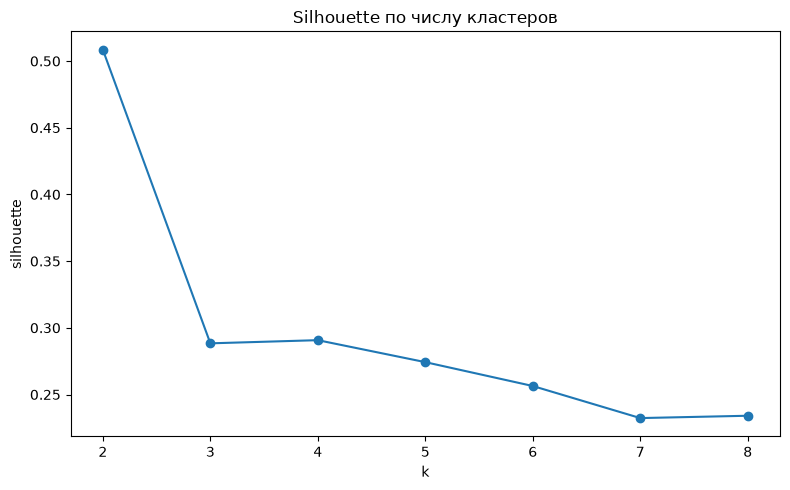

In [13]:
if RUN_CLUSTERABILITY:
    def hopkins_statistic(x, sample_size=3000, seed=SEED):
        rng = np.random.default_rng(seed)
        n = x.shape[0]
        m = min(sample_size, max(2, n // 10))

        sample_idx = rng.choice(n, size=m, replace=False)
        sample = x[sample_idx]

        mins = x.min(axis=0)
        maxs = x.max(axis=0)
        uniform_points = rng.uniform(mins, maxs, size=(m, x.shape[1]))

        nn = NearestNeighbors(n_neighbors=2, n_jobs=-1)
        nn.fit(x)

        u = nn.kneighbors(uniform_points, n_neighbors=1, return_distance=True)[0].ravel()
        w = nn.kneighbors(sample, n_neighbors=2, return_distance=True)[0][:, 1]

        return float(u.sum() / max(u.sum() + w.sum(), 1e-12))


    hopkins_values = [
        hopkins_statistic(X_pca, seed=SEED + i)
        for i in range(3)
    ]
    hopkins_df = pl.DataFrame({
        "run": [1, 2, 3],
        "hopkins": hopkins_values,
    })
    display(hopkins_df)

    cluster_range = range(2, 7 if FAST_MODE else 9)
    k_rows = []

    for k in cluster_range:
        model = KMeans(
            n_clusters=k,
            random_state=SEED,
            n_init=10,
            max_iter=300,
        )
        labels = model.fit_predict(X_pca)
        counts = np.bincount(labels, minlength=k)

        k_rows.append({
            "k": k,
            "inertia": float(model.inertia_),
            "silhouette": float(silhouette_score(X_pca, labels)),
            "davies_bouldin": float(davies_bouldin_score(X_pca, labels)),
            "calinski_harabasz": float(calinski_harabasz_score(X_pca, labels)),
            "min_cluster_share": float(counts.min() / len(labels)),
            "max_cluster_share": float(counts.max() / len(labels)),
        })

    k_metrics = pl.DataFrame(k_rows)
    display(k_metrics)

    plt.figure(figsize=(8, 5))
    plt.plot(k_metrics["k"], k_metrics["silhouette"], marker="o")
    plt.title("Silhouette по числу кластеров")
    plt.xlabel("k")
    plt.ylabel("silhouette")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "cluster_silhouette.png", dpi=140)
    plt.show()

In [14]:
if RUN_CLUSTERABILITY:
    rng = np.random.default_rng(SEED)
    null_repeats = 2 if FAST_MODE else 5
    null_rows = []

    X_null_base = X_pca[:min(len(X_pca), 15_000 if FAST_MODE else 20_000)].copy()

    for repeat in range(null_repeats):
        null_x = X_null_base.copy()
        for j in range(null_x.shape[1]):
            rng.shuffle(null_x[:, j])

        for k in cluster_range:
            model = KMeans(
                n_clusters=k,
                random_state=SEED + repeat,
                n_init=5,
                max_iter=250,
            )
            labels = model.fit_predict(null_x)
            null_rows.append({
                "repeat": repeat,
                "k": k,
                "silhouette": float(silhouette_score(null_x, labels)),
            })

    null_metrics = pl.DataFrame(null_rows)
    null_summary = (
        null_metrics.group_by("k")
        .agg([
            pl.col("silhouette").mean().alias("null_silhouette_mean"),
            pl.col("silhouette").std().fill_null(0).alias("null_silhouette_std"),
        ])
        .sort("k")
    )

    real_null = (
        k_metrics.select(["k", "silhouette"])
        .rename({"silhouette": "real_silhouette"})
        .join(null_summary, on="k")
        .with_columns(
            (pl.col("real_silhouette") - pl.col("null_silhouette_mean"))
            .alias("silhouette_lift")
        )
    )

    display(real_null)
    stability_rows = []
    stable_sample_n = min(len(X_pca), 10_000 if FAST_MODE else 20_000)
    common_idx = rng.choice(len(X_pca), size=stable_sample_n, replace=False)
    common_x = X_pca[common_idx]

    for k in cluster_range:
        label_sets = []
        repeats = 3 if FAST_MODE else 5
        for repeat in range(repeats):
            idx = rng.choice(len(X_pca), size=stable_sample_n, replace=False)
            model = KMeans(
                n_clusters=k,
                random_state=SEED + repeat,
                n_init=10,
                max_iter=300,
            )
            model.fit(X_pca[idx])
            label_sets.append(model.predict(common_x))

        aris = []
        for i in range(len(label_sets)):
            for j in range(i + 1, len(label_sets)):
                aris.append(adjusted_rand_score(label_sets[i], label_sets[j]))

        stability_rows.append({
            "k": k,
            "stability_ari_mean": float(np.mean(aris)),
            "stability_ari_min": float(np.min(aris)),
        })

    stability_df = pl.DataFrame(stability_rows)
    display(stability_df)

    cluster_diagnostics = (
        k_metrics
        .join(real_null.select(["k", "silhouette_lift"]), on="k")
        .join(stability_df, on="k")
    )
    cluster_diagnostics.write_csv(OUT_DIR / "clusterability_summary.csv")

k,real_silhouette,null_silhouette_mean,null_silhouette_std,silhouette_lift
i64,f64,f64,f64,f64
2,0.508486,0.446704,0.001338,0.061782
3,0.288369,0.236235,0.000876,0.052135
4,0.290744,0.230183,0.000491,0.060561
5,0.274269,0.201145,0.001645,0.073123
6,0.256377,0.156255,0.002772,0.100122
7,0.232332,0.145421,0.004953,0.086912
8,0.234081,0.14355,0.002203,0.090532


k,stability_ari_mean,stability_ari_min
i64,f64,f64
2,0.848227,0.624765
3,0.965373,0.922415
4,0.924651,0.870426
5,0.924728,0.838598
6,0.970179,0.951396
7,0.964168,0.952118
8,0.884099,0.771382


In [15]:
if RUN_CLUSTERABILITY and RUN_HDBSCAN:
    try:
        from sklearn.cluster import HDBSCAN

        hdbscan_rows = []
        for min_cluster_size in [100, 250, 500, 1000]:
            for min_samples in [None, 25, 50, 100]:
                model = HDBSCAN(
                    min_cluster_size=min_cluster_size,
                    min_samples=min_samples,
                    cluster_selection_method="eom",
                    metric="euclidean",
                    n_jobs=-1,
                )
                labels = model.fit_predict(X_pca)
                mask = labels >= 0
                n_clusters = len(np.unique(labels[mask])) if np.any(mask) else 0

                if n_clusters >= 2 and mask.sum() > n_clusters:
                    sil = float(silhouette_score(X_pca[mask], labels[mask]))
                else:
                    sil = np.nan

                hdbscan_rows.append({
                    "min_cluster_size": min_cluster_size,
                    "min_samples": 0 if min_samples is None else min_samples,
                    "clusters": n_clusters,
                    "noise_share": float(np.mean(~mask)),
                    "silhouette_non_noise": sil,
                })

        hdbscan_df = pl.DataFrame(hdbscan_rows)
        display(hdbscan_df.sort("silhouette_non_noise", descending=True, nulls_last=True))
        hdbscan_df.write_csv(OUT_DIR / "hdbscan_summary.csv")

    except ImportError:
        pass

min_cluster_size,min_samples,clusters,noise_share,silhouette_non_noise
i64,i64,i64,f64,f64
1000,0,2,0.78684,0.565832
500,0,2,0.7106,0.518823
250,0,2,0.66458,0.487625
100,0,2,0.62438,0.462641
100,100,2,0.62438,0.462641
…,…,…,…,…
1000,50,2,0.5298,0.437291
100,25,2,0.43322,0.413693
250,25,2,0.43322,0.413693


## 9. Soft profiles

Проверяем альтернативу жёсткой кластеризации: пользователь может быть смесью нескольких behavioural profiles.

NMF используется для оценки выраженности и смешанности таких профилей.

In [16]:
if RUN_SOFT_PROFILES:
    SOFT_FEATURES = [
        "search_to_cart_rate",
        "search_to_order_rate",
        "cat_to_cart_rate",
        "cat_to_order_rate",
        "cart_to_order_rate",
        "search_order_share",
        "search_gmv_share",
        "orders_recent_share",
        "gmv_recent_share",
    ]

    sf = cluster_features.select(["user_id", *SOFT_FEATURES]).drop_nulls()
    soft_sample_n = min(sf.height, 25_000 if FAST_MODE else 60_000)
    sf = sf.sample(n=soft_sample_n, seed=SEED, shuffle=True)

    R = np.column_stack([
        (rankdata(sf[c].to_numpy(), method="average") - 1.0) / max(sf.height - 1, 1)
        for c in SOFT_FEATURES
    ])
    R = np.clip(np.nan_to_num(R, nan=0.5), 0.0, 1.0)

    soft_rows = []
    nmf_models = {}

    for k in ([4, 5] if FAST_MODE else [3, 4, 5, 6, 7]):
        nmf = NMF(
            n_components=k,
            init="nndsvda",
            solver="cd",
            max_iter=600,
            random_state=SEED + k,
        )
        W = nmf.fit_transform(R)
        H = nmf.components_

        W = np.clip(W, 0, None)
        W = W / np.maximum(W.sum(axis=1, keepdims=True), 1e-12)

        max_w = W.max(axis=1)
        effective_count = 1.0 / np.maximum((W ** 2).sum(axis=1), 1e-12)

        soft_rows.append({
            "k": k,
            "reconstruction_error": float(nmf.reconstruction_err_),
            "mean_max_weight": float(max_w.mean()),
            "share_max_weight_ge_080": float(np.mean(max_w >= 0.80)),
            "mean_effective_profile_count": float(effective_count.mean()),
        })
        nmf_models[k] = (nmf, W, H)

    soft_summary = pl.DataFrame(soft_rows)
    display(soft_summary)
    soft_summary.write_csv(OUT_DIR / "soft_profile_summary.csv")

    chosen_k = 5 if 5 in nmf_models else int(soft_summary.sort("reconstruction_error")["k"][0])
    nmf, W, H = nmf_models[chosen_k]

    profile_rows = []
    for j in range(chosen_k):
        row = {"profile": j}
        for feature, value in zip(SOFT_FEATURES, H[j]):
            row[feature] = float(value)
        profile_rows.append(row)

    profile_table = pl.DataFrame(profile_rows)
    display(profile_table)
    profile_table.write_csv(OUT_DIR / "soft_profile_coordinates.csv")


k,reconstruction_error,mean_max_weight,share_max_weight_ge_080,mean_effective_profile_count
i64,f64,f64,f64,f64
3,91.875845,0.613053,0.03075,2.098063
4,66.280073,0.521854,0.02545,2.634479
5,40.818911,0.494155,0.047283,3.010067
6,24.240831,0.420178,0.001617,3.547425
7,13.875606,0.457971,0.0,3.500764


profile,search_to_cart_rate,search_to_order_rate,cat_to_cart_rate,cat_to_order_rate,cart_to_order_rate,search_order_share,search_gmv_share,orders_recent_share,gmv_recent_share
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0,27.59441,12.604779,0.0,1.846545,0.0,3.531842,3.476441,1.969817,2.098155
1,0.0,2.301002,5.724874,0.0,5.405608,13.692854,13.733592,1.574876,1.449099
2,0.0,0.0,0.0,1.284345,0.304316,0.860627,0.855381,11.336631,11.288624
3,0.0,5.502564,0.0,4.014312,7.051815,0.030912,0.009379,0.597271,0.678792
4,0.883631,0.0,4.861912,3.217062,0.241882,0.376702,0.390424,0.622802,0.616794


In [17]:
if RUN_SOFT_PROFILES and RUN_ARCHETYPAL_ANALYSIS_IF_AVAILABLE:
    try:
        from archetypes import AA

        aa = AA(
            n_archetypes=5,
            method="nnls",
            max_iter=300,
            tol=1e-4,
            n_init=1,
            random_state=SEED,
            verbose=False,
        )
        aa.fit(R)

        A = np.asarray(aa.archetypes_, dtype=np.float64)
        W_aa = np.asarray(aa.transform(R), dtype=np.float64)
        W_aa = np.clip(W_aa, 0, None)
        W_aa = W_aa / np.maximum(W_aa.sum(axis=1, keepdims=True), 1e-12)

        aa_rows = []
        for j in range(A.shape[0]):
            row = {"archetype": j}
            for feature, value in zip(SOFT_FEATURES, A[j]):
                row[feature] = float(value)
            aa_rows.append(row)

        aa_profiles = pl.DataFrame(aa_rows)
        display(aa_profiles)
        aa_profiles.write_csv(OUT_DIR / "archetypal_profiles_k5.csv")

        aa_mix = pl.DataFrame({
            "metric": [
                "mean_max_weight",
                "share_max_weight_ge_080",
                "mean_effective_profile_count",
            ],
            "value": [
                float(W_aa.max(axis=1).mean()),
                float(np.mean(W_aa.max(axis=1) >= 0.80)),
                float((1.0 / np.maximum((W_aa ** 2).sum(axis=1), 1e-12)).mean()),
            ],
        })
        display(aa_mix)
        aa_mix.write_csv(OUT_DIR / "archetypal_mixture_summary.csv")

    except ImportError:
        pass

Using NumPy backend


archetype,search_to_cart_rate,search_to_order_rate,cat_to_cart_rate,cat_to_order_rate,cart_to_order_rate,search_order_share,search_gmv_share,orders_recent_share,gmv_recent_share
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0,0.161772,0.615083,0.290747,0.407171,0.984392,0.715866,0.716232,0.229216,0.229216
1,0.472996,0.685975,0.312704,0.407171,0.723682,0.715866,0.716232,0.970884,0.97105
2,0.999128,0.590505,0.852301,0.407171,0.23956,0.670386,0.670724,0.229216,0.229216
3,0.159415,0.128633,0.321869,0.410099,0.124011,0.128633,0.128633,0.229216,0.229216
4,0.552759,0.791146,0.993415,0.998412,0.826988,0.239343,0.245569,0.858022,0.863622


metric,value
str,f64
"""mean_max_weight""",0.693221
"""share_max_weight_ge_080""",0.298283
"""mean_effective_profile_count""",1.881996


## 10. Validation regimes

Validation строится по времени.

`primary` anchors используются как основные независимые temporal regimes. Их 30-дневные target windows не пересекаются.

`stress` anchors используются отдельно для проверки поведения модели в дополнительных временных режимах.


In [18]:
def target_window(anchor: date):
    return anchor + timedelta(days=1), anchor + timedelta(days=HORIZON)

overlap_rows = []
for i, a in enumerate(PRIMARY_ANCHORS):
    a0, a1 = target_window(a)
    for j, b in enumerate(PRIMARY_ANCHORS):
        if j <= i:
            continue
        b0, b1 = target_window(b)
        overlap = max(0, (min(a1, b1) - max(a0, b0)).days + 1)
        overlap_rows.append({
            "anchor_a": a,
            "anchor_b": b,
            "overlap_days": overlap,
        })

overlap_df = pl.DataFrame(overlap_rows)
display(overlap_df)
assert overlap_df["overlap_days"].max() == 0, "Primary target windows пересекаются"

regime_rows = []
for a in PRIMARY_ANCHORS + STRESS_ANCHORS:
    if a + timedelta(days=HORIZON) > max_date:
        continue

    hist_start = max(min_date, a - timedelta(days=89))
    hist = data.filter(pl.col("event_date").is_between(hist_start, a, closed="both"))
    tgt = target_activity_for_anchor(a, include_users=False)

    regime_rows.append({
        "anchor": a,
        "role": "primary" if a in PRIMARY_ANCHORS else "stress",
        "history_days_available": (a - min_date).days + 1,
        "active_users_90d": hist["user_id"].n_unique(),
        "orders_90d": float(hist["to_ord"].sum()),
        "gmv_90d": float(hist["gmv"].sum()),
        "future_buyers": tgt.filter(pl.col("future_gmv") > 0).height,
        "future_zero_share": 1.0 - tgt.filter(pl.col("future_gmv") > 0).height / all_users.height,
        "future_mean_gmv": float(tgt["future_gmv"].sum()) / all_users.height,
        **future_calendar_values(a),
    })

regime_audit = pl.DataFrame(regime_rows).sort("anchor")
display(regime_audit)
regime_audit.write_csv(OUT_DIR / "validation_regime_audit.csv")


anchor_a,anchor_b,overlap_days
date,date,i64
2025-07-30,2025-09-10,0
2025-07-30,2025-10-22,0
2025-07-30,2026-01-14,0
2025-09-10,2025-10-22,0
2025-09-10,2026-01-14,0
2025-10-22,2026-01-14,0


anchor,role,history_days_available,active_users_90d,orders_90d,gmv_90d,future_buyers,future_zero_share,future_mean_gmv,target_special_days,target_newyear_days,target_weekend_days
date,str,i64,i64,f64,f64,i64,f64,f64,f64,f64,f64
2025-06-18,"""stress""",169,220998,1.474441e6,5.2049e7,112212,0.551152,76.916621,0.0,0.0,8.0
2025-07-30,"""primary""",211,225571,1.601491e6,5.5691e7,122247,0.511012,87.394139,0.0,0.0,8.0
2025-09-10,"""primary""",253,230865,1.792185e6,6.1240e7,125692,0.497232,89.020345,0.0,0.0,8.0
2025-10-22,"""primary""",295,237465,1.959867e6,6.6214e7,134147,0.463412,93.352304,3.0,0.0,8.0
2025-12-03,"""stress""",337,246688,2.087813e6,6.8994e7,143878,0.424488,110.036913,19.0,19.0,8.0
2025-12-15,"""stress""",349,250000,2.162737e6,7.1270e7,140770,0.43692,101.425944,19.0,19.0,8.0
2026-01-14,"""primary""",379,250000,2.24937e6,7.3825e7,135165,0.45934,84.034042,0.0,0.0,8.0


## 11. Выводы

* 30-дневный target содержит большую долю нулевых значений.
* Положительный GMV имеет тяжёлый верхний хвост.
* Purchase frequency и recency сильно связаны с будущим GMV.
* `future_order_days` хорошо разделяет разные уровни будущего GMV, но используется только как диагностическая величина.
* Search / Catalog profile имеет некоторую временную устойчивость.
* Сильного естественного hard-cluster разбиения пользователей не наблюдается.
* Распределение target и общая активность заметно меняются между временными режимами, поэтому validation должна быть temporal.


## 12. EDA metrics

In [19]:
summary_rows = [
    {"metric": "rows", "value": str(data.height)},
    {"metric": "users", "value": str(all_users.height)},
    {"metric": "date_min", "value": str(min_date)},
    {"metric": "date_max", "value": str(max_date)},
    {"metric": "target_zero_share_min", "value": f"{float(target_summary['zero_share'].min()):.6f}"},
    {"metric": "target_zero_share_max", "value": f"{float(target_summary['zero_share'].max()):.6f}"},
    {"metric": "mean_30d_gmv_min", "value": f"{float(target_summary['mean_gmv'].min()):.6f}"},
    {"metric": "mean_30d_gmv_max", "value": f"{float(target_summary['mean_gmv'].max()):.6f}"},
]

if RUN_CLUSTERABILITY:
    best_cluster_row = cluster_diagnostics.sort("silhouette", descending=True).row(0, named=True)
    summary_rows.extend([
        {"metric": "cluster_best_k_by_silhouette", "value": str(best_cluster_row["k"])},
        {"metric": "cluster_best_silhouette", "value": f"{float(best_cluster_row['silhouette']):.6f}"},
        {"metric": "cluster_silhouette_lift_vs_null", "value": f"{float(best_cluster_row['silhouette_lift']):.6f}"},
        {"metric": "cluster_stability_ari", "value": f"{float(best_cluster_row['stability_ari_mean']):.6f}"},
    ])

summary = pl.DataFrame(summary_rows)
summary.write_csv(OUT_DIR / "eda_summary.csv")
display(summary)

metric,value
str,str
"""rows""","""30631006"""
"""users""","""250000"""
"""date_min""","""2025-01-01"""
"""date_max""","""2026-02-13"""
"""target_zero_share_min""","""0.424488"""
…,…
"""mean_30d_gmv_max""","""110.036913"""
"""cluster_best_k_by_silhouette""","""2"""
"""cluster_best_silhouette""","""0.508486"""
